In [12]:
import numpy as np
import numpy.random as rand
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score
import statsmodels.api as sm

In [2]:
rand.seed(1)

In [3]:
x = rand.normal(0, 1, size=100)
eps = rand.normal(0, 0.25, size=100)
y = -1 + 0.5 * x + eps

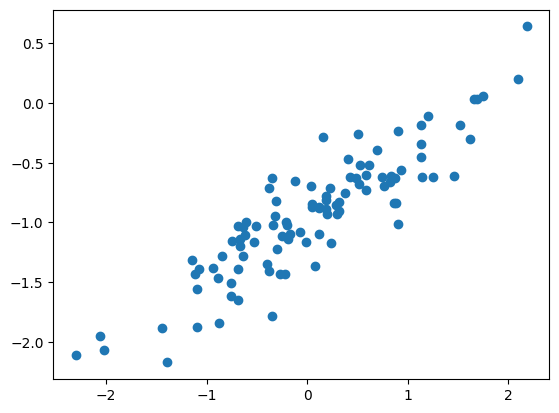

In [4]:
plt.scatter(x, y)
plt.show()

In [5]:
model = LinearRegression()
model.fit(x.reshape(-1, 1), y)

print(f"beta_0 = {model.intercept_}, beta_1 = {model.coef_[0]}")

beta_0 = -0.9632466175754496, beta_1 = 0.5238567834127927


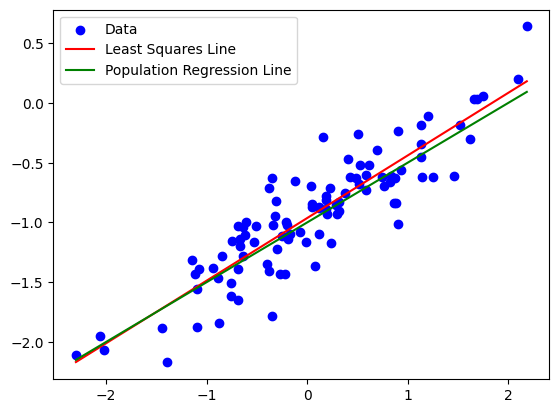

In [6]:
plt.scatter(x, y, label='Data', color='blue')

x_vals = np.linspace(min(x), max(x), 100)
y_pred = model.intercept_ + model.coef_[0] * x_vals
plt.plot(x_vals, y_pred, label='Least Squares Line', color='red')

y_population = -1 + 0.5 * x_vals
plt.plot(x_vals, y_population, label='Population Regression Line', color='green')

plt.legend()
plt.show()

In [8]:
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(x.reshape(-1, 1))

poly_model = LinearRegression()
poly_model.fit(X_poly, y)

y_poly_pred = poly_model.predict(X_poly)

r2_poly = r2_score(y, y_poly_pred)

r2_linear = r2_score(y, model.predict(x.reshape(-1, 1)))

print(f"R² score (Linear Model): {r2_linear}")
print(f"R² score (Polynomial Model): {r2_poly}")

R² score (Linear Model): 0.7997346204862734
R² score (Polynomial Model): 0.7998024699274676


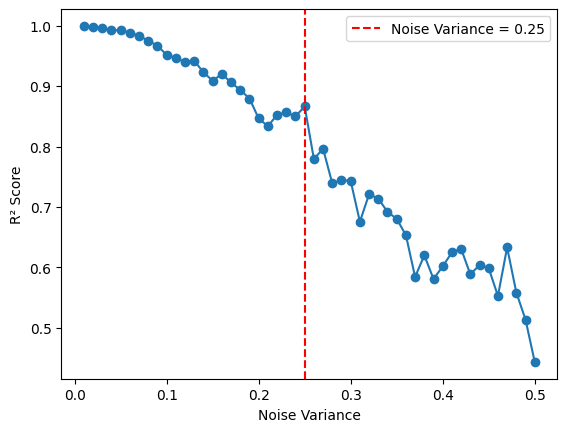

In [9]:
x = rand.normal(0, 1, 100)
noise_variance_values = np.array(range(50, 0, -1)) / 100
errors = []

for variance in noise_variance_values:
    eps = rand.normal(0, variance, 100)
    y = -1 + 0.5 * x + eps
    model = LinearRegression()
    model.fit(x.reshape(-1, 1), y)
    y_pred = model.predict(x.reshape(-1, 1))
    r2 = r2_score(y, y_pred)
    errors.append(r2)

plt.plot(noise_variance_values, errors, marker='o')
plt.axvline(x=0.25, color='red', linestyle='--', label='Noise Variance = 0.25')
plt.legend()
plt.xlabel('Noise Variance')
plt.ylabel('R² Score')
plt.show()

In [15]:
def calculate_confidence_intervals(x, y, alpha=0.05):
    x_with_intercept = sm.add_constant(x)
    model = sm.OLS(y, x_with_intercept).fit()
    conf_intervals = model.conf_int(alpha=alpha)
    return conf_intervals, model.params

original_conf_intervals, original_params = calculate_confidence_intervals(x, y)
print("Original Data Set:")
print(f"β₀ (Intercept): {original_params[0]} with CI {original_conf_intervals[0]}")
print(f"β₁ (Slope): {original_params[1]} with CI {original_conf_intervals[1]}")

noisier_eps = rand.normal(0, 0.5, size=100)
y_noisier = -1 + 0.5 * x + noisier_eps
noisier_conf_intervals, noisier_params = calculate_confidence_intervals(x, y_noisier)
print("\nNoisier Data Set:")
print(f"β₀ (Intercept): {noisier_params[0]} with CI {noisier_conf_intervals[0]}")
print(f"β₁ (Slope): {noisier_params[1]} with CI {noisier_conf_intervals[1]}")

less_noisy_eps = rand.normal(0, 0.1, size=100)
y_less_noisy = -1 + 0.5 * x + less_noisy_eps
less_noisy_conf_intervals, less_noisy_params = calculate_confidence_intervals(x, y_less_noisy)
print("\nLess Noisy Data Set:")
print(f"β₀ (Intercept): {less_noisy_params[0]} with CI {less_noisy_conf_intervals[0]}")
print(f"β₁ (Slope): {less_noisy_params[1]} with CI {less_noisy_conf_intervals[1]}")

Original Data Set:
β₀ (Intercept): -1.000831355585256 with CI [-1.00282891 -0.99883381]
β₁ (Slope): 0.500310758505473 with CI [0.49832312 0.5022984 ]

Noisier Data Set:
β₀ (Intercept): -1.102143252679451 with CI [-1.2067147 -0.9975718]
β₁ (Slope): 0.5080503750075419 with CI [0.40399758 0.61210317]

Less Noisy Data Set:
β₀ (Intercept): -0.997035221306334 with CI [-1.016034   -0.97803644]
β₁ (Slope): 0.4837314174468266 with CI [0.46482687 0.50263597]
